In [5]:
from pipeline import get_feature_names, get_target_name, build_model_pipeline
import matplotlib.pyplot as plt
from sklearn.model_selection import (train_test_split)
from sklearn.linear_model import (
    LogisticRegression
    )
from sklearn.ensemble import (
    RandomForestClassifier
    )
from sklearn.neural_network import(
    MLPClassifier
    )

import data_loader
import evaluation 

## TESTING
import importlib

PATH_DATA ='data/raw/Telco_customer_churn.xlsx'
SEED = 4586

target_recall=0.8
min_precision=0.65

generic_colors : list[str] = [ "#0000ff", "#f63400", "#9d02d7", "#ff6ecd", "#9b0000" ]
evaluation.set_color_cycle(generic_colors)



In [6]:
df = data_loader.load_churn_data(PATH_DATA)

X = df[get_feature_names(False)]
y = df[get_target_name(False)]

X_train, X_test, y_train, y_test = train_test_split(X, y, random_state=SEED, stratify=y)
y_test.value_counts()

Churn Value
0    1294
1     467
Name: count, dtype: int64

In [7]:
pipeline_lr = build_model_pipeline(
        LogisticRegression(),
        scale=True
    )

pipeline_rfc = build_model_pipeline(
        RandomForestClassifier(),
        scale=False
    )

pipeline_mlp = build_model_pipeline(
        MLPClassifier(),
        scale=True
    )


models = {
    'lr':pipeline_lr,
    'rfc':pipeline_rfc,
    'mlp':pipeline_mlp
}

models_grid_params = {
    'lr':{
        'param_grid':{
            'model__solver': ['saga'],
            'model__l1_ratio': [0, 0.25, 0.5, 0.75, 1],  # 0 = pure L2, 1 = pure L1
            'model__C': [0.1, 1.0, 10.0],
            'model__max_iter': [1000],  # Increased so saga converges cleanly
            'model__class_weight':['balanced'],
            'model__random_state':[SEED]
            },
        'scoring':'average_precision'
        },
    'rfc':{
       'param_grid':{
           'model__random_state':[SEED],
           'model__n_estimators': [100, 250, 500],
           'model__max_features': ['sqrt', 'log2'],
           'model__max_depth':[10, 20, 30],
           'model__min_samples_leaf':[3, 7],
           'model__min_samples_split': [2, 5, 10],
            'model__class_weight': ['balanced', 'balanced_subsample'],
           },
        'scoring':'average_precision' 
        },
    'mlp':{
        'param_grid':{
           'model__random_state':[SEED],
            'model__hidden_layer_sizes':[(32,), (64, 32), (16,)],
            'model__activation':['relu', 'tanh'],
            'model__solver':['adam'],
            'model__alpha':[0.0001, 0.05, 0.1],
            'model__learning_rate_init':[0.001, 0.01],
            'model__max_iter':[300, 500],
            'model__early_stopping':[True],
            'model__validation_fraction':[0.15]
            },
        'scoring':'average_precision'
        }
    }

In [8]:
grid_results = evaluation.random_grid_search_models(
        models = models,
        models_grid_params=models_grid_params,
        X_train=X_train,
        y_train=y_train,
        X_test=X_test,
        seed=SEED,
    )

In [9]:
evaluation.add_stats_to_grid_results(grid_results, y_test, target_recall)

In [10]:
evaluation.display_grid_results(grid_results)

RESULTS FOR "lr"
Best Parameters: {'model__solver': 'saga', 'model__random_state': 4586, 'model__max_iter': 1000, 'model__l1_ratio': 0, 'model__class_weight': 'balanced', 'model__C': 10.0}
Best CV average_precision: 0.6731
Threshold ( Recall = 0.80 | Precision = 0.55 ) = 0.50
RESULTS FOR "rfc"
Best Parameters: {'model__random_state': 4586, 'model__n_estimators': 500, 'model__min_samples_split': 2, 'model__min_samples_leaf': 7, 'model__max_features': 'sqrt', 'model__max_depth': 10, 'model__class_weight': 'balanced'}
Best CV average_precision: 0.6865
Threshold ( Recall = 0.80 | Precision = 0.57 ) = 0.52
RESULTS FOR "mlp"
Best Parameters: {'model__validation_fraction': 0.15, 'model__solver': 'adam', 'model__random_state': 4586, 'model__max_iter': 300, 'model__learning_rate_init': 0.01, 'model__hidden_layer_sizes': (32,), 'model__early_stopping': True, 'model__alpha': 0.1, 'model__activation': 'relu'}
Best CV average_precision: 0.6780
Threshold ( Recall = 0.80 | Precision = 0.54 ) = 0.31


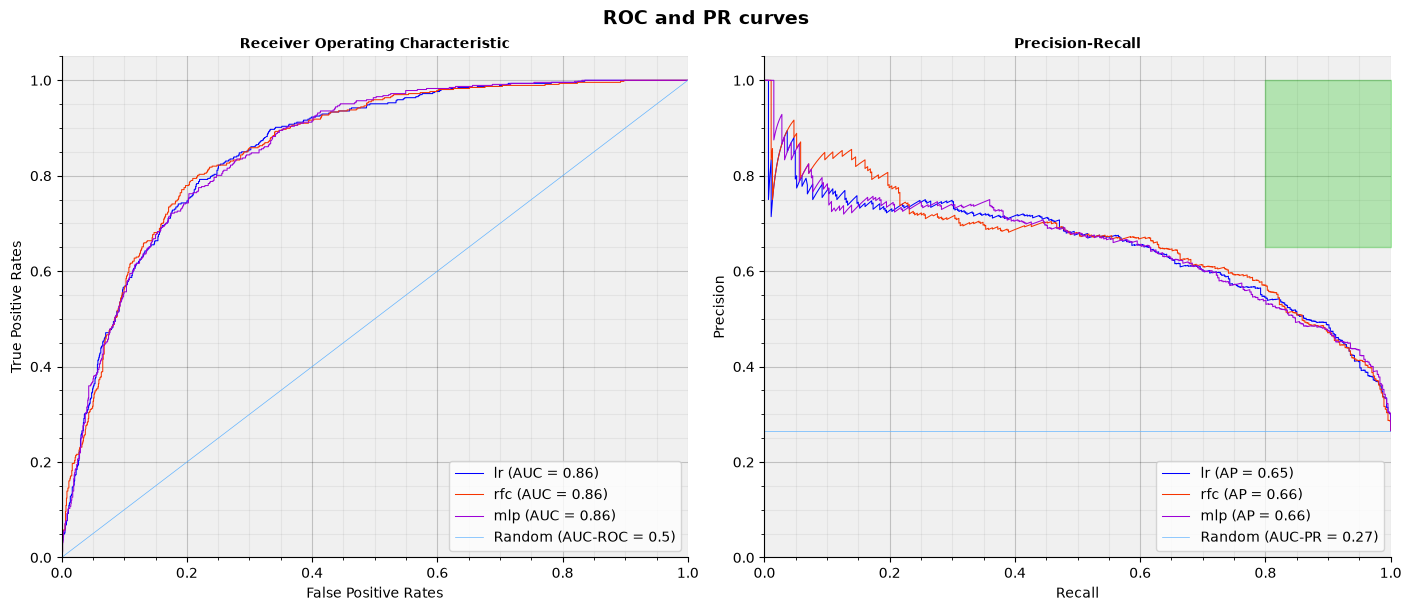

In [11]:
evaluation.plot_multiple_roc_pr(
    y_true=y_test,
    results=grid_results,
    target_recall=target_recall,
    min_precision=min_precision,
    figsize=(14,6)
)
plt.show()

In [12]:
for model in grid_results:
    evaluation.quick_evaluation(y_test, grid_results[model]['y_proba'], grid_results[model]['stats']['threshold'], model)

EVALUATION OF LR AT THRESHOLD 0.5032665601116766
              precision    recall  f1-score   support

           0       0.91      0.76      0.83      1294
           1       0.55      0.80      0.65       467

    accuracy                           0.77      1761
   macro avg       0.73      0.78      0.74      1761
weighted avg       0.82      0.77      0.78      1761

acc			0.77
recall			0.80
precision		0.55
f1-score		0.65
average precision	0.65
EVALUATION OF RFC AT THRESHOLD 0.5217596744511043
              precision    recall  f1-score   support

           0       0.92      0.78      0.84      1294
           1       0.57      0.80      0.67       467

    accuracy                           0.79      1761
   macro avg       0.74      0.79      0.76      1761
weighted avg       0.82      0.79      0.80      1761

acc			0.79
recall			0.80
precision		0.57
f1-score		0.67
average precision	0.66
EVALUATION OF MLP AT THRESHOLD 0.3078625245322121
              precision    recall  f1-s